# Purpose
## The primary task is to find correlations between the price of a vehcile and other attributes, such as year, make, etc. 

## The secondary task is to explore any correlation that exists between other attributes. 

# There are some preliminary preparation tasks you should complete before the EDA tasks.

1.	Dataset Selection 


a.	Adequacy Check: Make sure that the dataset is large enough and representative of the problem you're trying to solve. Ensure it includes relevant variables for the analysis you're aiming to perform. 


The datasets contain over 9000 rows of data, more than enough to establish findings. However, if we want to predict the price of a Tesla Model Y or a Ford F-150, we only have a dozen or so rows for those specific makes/models. We will proceed with the EDA, but adjust our goals based on appropriate size of data. For example, we might target a Hyundai Palisade if this make/model contains a larger dataset than other makes/models.

1.	Dataset Selection 

b.	Data Integrity: Check for source information and understand its data collection methodology and if there are any potential biases in the dataset. Sometimes datasets come with unclear or misleading variable names, so it’s essential to interpret them in context. 


The data comes from https://www.kaggle.com/datasets/ahmedgmy/cars-raw-dataset

Kaggle is a common dataset sharing website and while I do not know the author Ahmed Gamal personally, I verified the data by searching the VINs of cars within the dataset on CARFAX. CARFAX verified several makes/models of different cars when I searched the VINs, verifiying the authenticity of the dataset. 

There are various scores to reliability, dealer seller rating, etc. While these could be skewed or bias, we will press forward with our analysis. However the data seems to be consistent with normal Google/seller reviews. For example, BG Motorcars in IL had a Seller Rating of 4.1 and on Google, it had 3.9 out of 5 stars. 

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
# Load the data
cars_df = pd.read_csv("cars_raw.csv")

2.	Data Cleaning and Preparation 
a.	Handle missing values or outliers  


In [59]:

# Drop rows where Price is "Not Priced"
cars_df = cars_df[cars_df['Price'] != 'Not Priced']


# We have to change price to number
# Drop dollar sign
cars_df['Price'] = cars_df['Price'].str.replace('$', '', regex=False)

# Drop comma
cars_df['Price'] = cars_df['Price'].str.replace(',', '', regex=False)

# Convert to int
cars_df['Price'] = cars_df['Price'].astype(int)


# Count of missing values per column
missing_sum = cars_df.isnull().sum()

# Percentage of missing values per column
missing_mean = cars_df.isnull().mean()

# Rows with any missing values
missing_rows = cars_df[cars_df.isnull().any(axis=1)]

# Print summary
print(f"Total missing values in DataFrame: {missing_sum.sum()}")
print(f"Average missing percentage per column: {missing_mean.mean():.2%}")
# While we could use some imputation for things such as missing miles, or price, that would require us to find associated make/models of the same year, and dropping the frames is easier.
cleaned_cars_df = cars_df.dropna()

# Make a new column called year, to add a numerical col instead of a categorical one.
cleaned_cars_df['Age'] = 2025 - cleaned_cars_df['Year']
cleaned_cars_df.drop(columns=['Year'], inplace=True)



Total missing values in DataFrame: 222
Average missing percentage per column: 0.07%


C:\Users\Gabe\AppData\Local\Temp\ipykernel_39088\400087713.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_cars_df['Age'] = 2025 - cleaned_cars_df['Year']
C:\Users\Gabe\AppData\Local\Temp\ipykernel_39088\400087713.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_cars_df.drop(columns=['Year'], inplace=True)


## b. Recoding or encoding of variables   

## c. Data transformation if certain variables are skewed or have extreme values  

## d. Normalization or Standardization (Note. If you're going to apply machine learning algorithms (e.g., clustering, classification), it’s critical to know if normalization or standardization is applied to your variables)   

In [60]:
#! Note! We will standardize and encode AFTER separating by make/model, as the make model will have their own distributions and we want to keep that information intact.
#! However, we can write the functions NOW, so we can use them later.
def encode_categorical(df, columns):
    for column in columns:
        df[column] = df[column].astype('category').cat.codes
    return df

def standardize_numerical(df, columns):
    for column in columns:
        mean = df[column].mean()
        std = df[column].std()
        df[column] = (df[column] - mean) / std
    return df

# For models comparing against each other, we will drop constant columns, such as "comfort rating". This is easier just to keep only the columns we want.
unique_col = "Model"
numerical_columns = ["ConsumerRating", "ConsumerReviews", "SellerRating", "SellerReviews", "Mileage", "Age"]
# This is a more refined list of numerical columns
columns_of_interest = ['Price', 'Mileage', 'Age', 'ConsumerRating', 'SellerRating', "ConsumerReviews", 'SellerReviews']

# What we want to predict
target = "Price"


# State and zipcode might be redundant, but we will keep them for now.
categorical_columns = ['SellerName', 'State', 'DealType','Zipcode']

relevant_columns = numerical_columns + categorical_columns + [target] + [unique_col]

cleaned_cars_df = cleaned_cars_df[relevant_columns]
cleaned_cars_df[:3]


,ConsumerRating,ConsumerReviews,SellerRating,SellerReviews,Mileage,Age,SellerName,State,DealType,Zipcode,Price,Model
0,4.6,45,3.3,3,29403,6,CarMax Murrieta - Now offering Curbside Pickup...,CA,Great,92562,39998,Sienna SE
1,4.8,817,4.8,131,32929,7,Giant Chevrolet,CA,Good,93292,49985,F-150 Lariat
2,4.7,495,4.6,249,23173,8,Gill Auto Group Madera,CA,Good,93637,41860,1500 Laramie


In [61]:
# Count unique values and sort by frequency (descending)
mode_counts = cleaned_cars_df['Model'].value_counts()

# Print the top 20 models by count
print("Top 20 unique values in 'Model' sorted by count:")
print(mode_counts.head(7))


'''
The most popular models for sale are Grand Cherokee Limited, CR-V, and X5. 
When we compare models, we have to be cognizant of variances between generations.

For example, the Grand Cherokee is fairly easy because it's the same car/trim across several rows.
At a glance, we assume the X5 is probably the same as other X5s, but the xDrive40i and xDrive35i are different generations,
leading to variances in pricing and reliability. 

Further analysis might compare models against models, but we should also save off the top 3 models against themselves for model-specific analysis
'''

grand_cherokee_df = cleaned_cars_df[cleaned_cars_df['Model'] == "Grand Cherokee Limited"]
crv_df = cleaned_cars_df[cleaned_cars_df['Model'] == "CR-V EX-L"]
x5_drive40i = cleaned_cars_df[cleaned_cars_df['Model'] == "X5 xDrive40i"]

top_3_cars_df= [grand_cherokee_df,crv_df,x5_drive40i]

Top 20 unique values in 'Model' sorted by count:
Model
Grand Cherokee Limited    265
CR-V EX-L                 189
X5 xDrive40i              164
XT5 Luxury                140
RAV4 LE                   112
GX 460 Base               111
X3 xDrive30i              108
Name: count, dtype: int64


In [62]:
# Just a simple printout to verify the data
grand_cherokee_df[:3]

,ConsumerRating,ConsumerReviews,SellerRating,SellerReviews,Mileage,Age,SellerName,State,DealType,Zipcode,Price,Model
243,4.8,224,4.7,4644,32858,6,Scott Clark Toyota,NC,Great,28105,35500,Grand Cherokee Limited
276,4.8,334,4.3,1366,16929,8,Bill Luke Chrysler Jeep Dodge RAM,AZ,Great,85015,27575,Grand Cherokee Limited
300,4.8,224,4.5,1343,33995,6,Mercedes-Benz of Houston North,TX,Good,77090,34991,Grand Cherokee Limited


1.	Describe the Variable Characteristics with Summary Statistics  
a.	Provide description of the variables you are using in this project.  


In [63]:
from prettytable import PrettyTable
import pandas as pd

# Notes dictionary
notes_dict = {
    'Price': 'Target variable we want to predict',
    'DealType': 'Based on MSRP/KBB Value of car vs price',
    'ConsumerRating': 'Average consumer rating of the car',
    'ConsumerReviews': 'Number of consumer reviews for the car',
    'SellerRating': 'Average seller rating of the car',
    'SellerReviews': 'Number of seller reviews for the car',
    'Mileage': 'Mileage of the car in miles',
    'State': 'State where the car is being sold',
    'Zipcode': 'Zipcode where the car is being sold',
    'SellerName': 'Name of the seller, encoded as a category',
    'Age': 'Age of the car in years, calculated from the current year minus the year of manufacture'
}

# Create the PrettyTable
table = PrettyTable()
table.field_names = ["Column Name", "Data Type", "Example Data", "Notes"]

# Helper function to classify type
def classify_type(series):
    if pd.api.types.is_numeric_dtype(series):
        return "Numerical"
    elif series.nunique(dropna=True) == 2:
        return "Binary"
    else:
        return "Categorical"

# Fill the table
for col in grand_cherokee_df.columns:
    col_name = col
    data_type = classify_type(grand_cherokee_df[col])
    example_data = str(grand_cherokee_df[col].iloc[0])
    note = notes_dict.get(col, "")  # Get note from dictionary if exists
    table.add_row([col_name, data_type, example_data, note])

# Print the table
print(table)


+-----------------+-------------+------------------------+-----------------------------------------------------------------------------------------+
|   Column Name   |  Data Type  |      Example Data      |                                          Notes                                          |
+-----------------+-------------+------------------------+-----------------------------------------------------------------------------------------+
|  ConsumerRating |  Numerical  |          4.8           |                            Average consumer rating of the car                           |
| ConsumerReviews |  Numerical  |          224           |                          Number of consumer reviews for the car                         |
|   SellerRating  |  Numerical  |          4.7           |                             Average seller rating of the car                            |
|  SellerReviews  |  Numerical  |          4644          |                           Number of seller revi

In [64]:
# At this point, we can standardize and encode the data.
# Create a new list to store the modified DataFrames
processed_dfs = []

for df in top_3_cars_df:
    df = df.copy()  # Avoid SettingWithCopyWarning by working on a copy
    df.drop(columns=['Model'], inplace=True)  # Drop the model column as it's not needed for encoding/standardization
    df = encode_categorical(df, categorical_columns)

    #! NOTE: I initially standardized the numerical columns, but I find that the numerical columns are already on a similar scale and the variance in data is crucial to understanding 
    # differences betweeen cars. I have left this in to demonstrate my ability to standardize, but I didn't find it useful for this exercise.

    # Also, Year is already standardized as Age, so we don't need to standardize it again.
    # df = standardize_numerical(df, numerical_columns)
    
    processed_dfs.append(df)  # Store the processed DataFrame

# Optionally overwrite the original list
top_3_cars_df = processed_dfs


# 2. Conduct Univariate Analysis  
## a. Calculate descriptive statistics (mean, median, mode, variance, skewness, kurtosis) of the key variables in your dataset  

In [65]:
def calculate_stats(df,col_name:str):
    print(df[col_name].describe())
    print("Skewness:", df[col_name].skew())
    print("Kurtosis:", df[col_name].kurt())


# Numerical summary statistics for Grand Cherokee Limited
print(grand_cherokee_df['Price'].describe())
print("Skewness:", grand_cherokee_df['Price'].skew())
print("The data ought to be -0.5 and 0.5. The skew is slightly negative, so slightly left skewed.")
print("Kurtosis:", grand_cherokee_df['Price'].kurt())
print("Kurtosis less than 3, so flatter tails and flatter peak. Also known as platykurtic distribution.")


count      265.000000
mean     35236.486792
std       6472.162817
min       9985.000000
25%      31949.000000
50%      34999.000000
75%      38900.000000
max      51322.000000
Name: Price, dtype: float64
Skewness: -0.3509725162755977
The data ought to be -0.5 and 0.5. The skew is slightly negative, so slightly left skewed.
Kurtosis: 1.0129101152728839
Kurtosis less than 3, so flatter tails and flatter peak. Also known as platykurtic distribution.


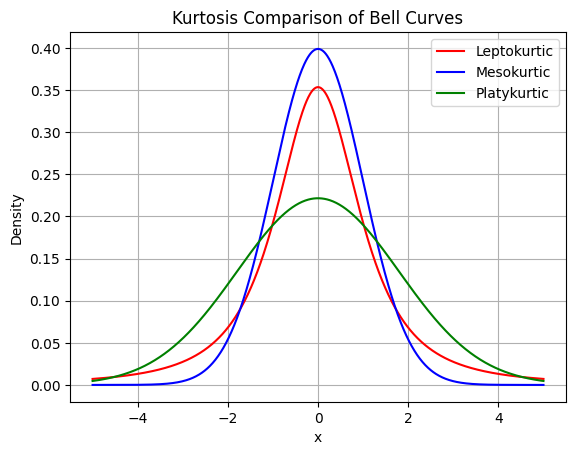

In [66]:
#! This is purely for me to compare and contrast different bell curves. 

x = np.linspace(-5, 5, 1000)

# Mesokurtic (normal distribution)
y_norm = norm.pdf(x)

# Leptokurtic (t-distribution with low df -> heavy tails)
y_lepto = t.pdf(x, df=2)

# Platykurtic (flattened normal, via wider std deviation)
y_platy = norm.pdf(x, scale=1.8)

plt.plot(x, y_lepto, label='Leptokurtic', color='red')
plt.plot(x, y_norm, label='Mesokurtic', color='blue')
plt.plot(x, y_platy, label='Platykurtic', color='green')

plt.legend()
plt.title('Kurtosis Comparison of Bell Curves')
plt.xlabel('x')
plt.ylabel('Density')
plt.grid(True)
plt.show()


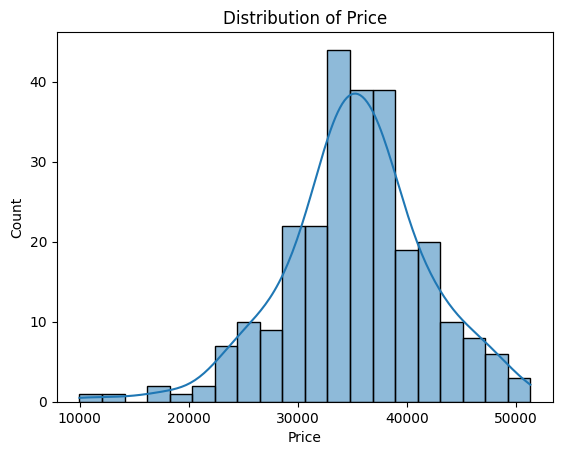

In [67]:
# Bar chart with smoothing line for Price
sns.histplot(grand_cherokee_df['Price'], kde=True)
plt.title("Distribution of Price")
plt.show()

In [68]:
print("We can now visualize the skew. We'll do a boxplot to see the true outliers.")

We can now visualize the skew. We'll do a boxplot to see the true outliers.


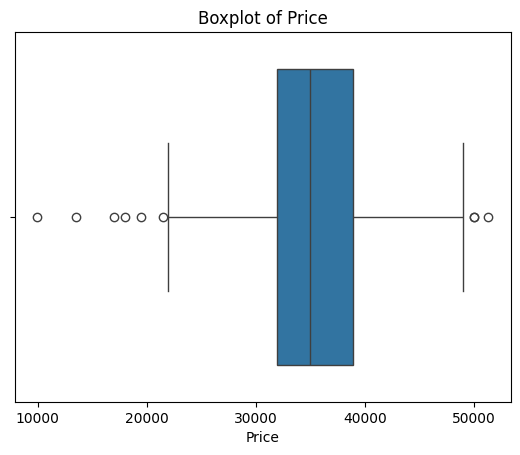

In [69]:
# Boxplot for Price
sns.boxplot(x=grand_cherokee_df['Price'])
plt.title("Boxplot of Price")
plt.show()

In [70]:
# We can see the Price below 20k is an outlier, as is the price above 50k. We'll drop these outliers for a new df. However, these points might represent some relationships, such as old cars or cars with high mileage, so we'll retain our old dataset.
grand_cherokee_df_without_price_outliers = grand_cherokee_df[(grand_cherokee_df['Price'] >= 20000) & (grand_cherokee_df['Price'] <= 50000)]

In [71]:
print("Skewness:", grand_cherokee_df_without_price_outliers['Price'].skew())
print("Kurtosis:", grand_cherokee_df_without_price_outliers['Price'].kurt())
print("The data overall points is less skewed. Very mild tails, leading to less outliers to skew out findings.")

Skewness: 0.07810128651468572
Kurtosis: -0.07274599573683505
The data overall points is less skewed. Very mild tails, leading to less outliers to skew out findings.


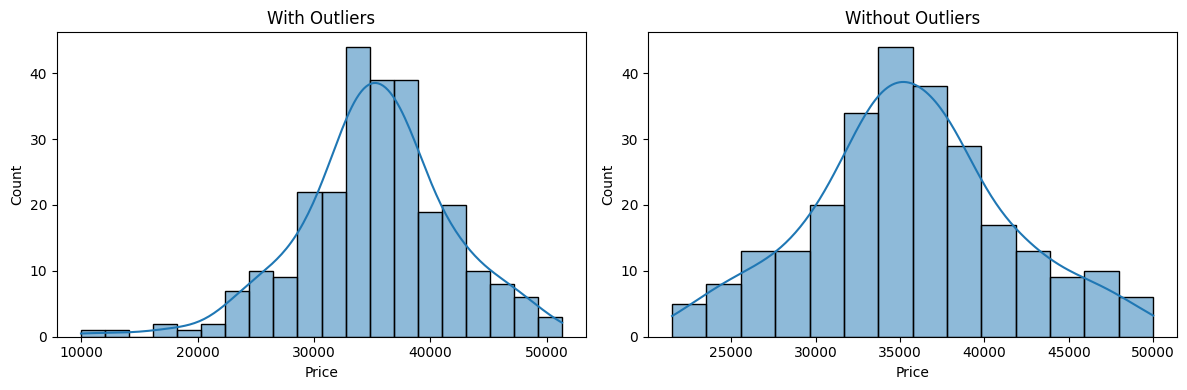

In [72]:
# Plotting both side by side to see the skew with and without outliers

fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 1 row, 2 columns

sns.histplot(grand_cherokee_df['Price'], kde=True, ax=axes[0])
axes[0].set_title("With Outliers")

sns.histplot(grand_cherokee_df_without_price_outliers['Price'], kde=True, ax=axes[1])
axes[1].set_title("Without Outliers")

plt.tight_layout()
plt.show()

In [73]:
print("We can see that when we remove the outliers, the distribution of Price is more normal, with a slight right skew. This is expected, as most cars will have mileage in the 20k-100k range, with some outliers for low/high mileage cars.")

We can see that when we remove the outliers, the distribution of Price is more normal, with a slight right skew. This is expected, as most cars will have mileage in the 20k-100k range, with some outliers for low/high mileage cars.


3.	Conduct Bivariate Analysis  
a.	Calculate covariance and correlation 
i.	Utilize Pearson correlation for continuous values.  
ii.	For categorical variables, you could explore additional methods like Spearman rank correlation (Optional)  



In [74]:
''' 
The Pearson correlation coefficient (also called Pearson's r) is a statistical measure that quantifies the linear relationship between two continuous variables.

+1: Perfect positive linear correlation (as one goes up, the other goes up).

0: No linear correlation.

−1: Perfect negative linear correlation (as one goes up, the other goes down).

'''

# Pearson correlation between numerical features and target variables in grand_cherokee_df

print("Pearson correlation matrix (Grand Cherokee Limited):")
print(grand_cherokee_df_without_price_outliers[columns_of_interest].corr(method='pearson'))



Pearson correlation matrix (Grand Cherokee Limited):
                    Price   Mileage       Age  ConsumerRating  SellerRating  \
Price            1.000000 -0.750659 -0.852717       -0.531472     -0.000574   
Mileage         -0.750659  1.000000  0.622290        0.379086     -0.062893   
Age             -0.852717  0.622290  1.000000        0.488603     -0.021733   
ConsumerRating  -0.531472  0.379086  0.488603        1.000000      0.101608   
SellerRating    -0.000574 -0.062893 -0.021733        0.101608      1.000000   
ConsumerReviews -0.712393  0.490781  0.779042        0.646593      0.028733   
SellerReviews   -0.061191 -0.005124 -0.031196        0.125902      0.286767   

                 ConsumerReviews  SellerReviews  
Price                  -0.712393      -0.061191  
Mileage                 0.490781      -0.005124  
Age                     0.779042      -0.031196  
ConsumerRating          0.646593       0.125902  
SellerRating            0.028733       0.286767  
ConsumerReview

In [75]:
print("We observe that as Mileage increases, Price tends to decrease, with a correlation of -0.75. Similarly, as Age increases, Price also decreases. Seller reviews and ratings generally have little effect on the Price. However, Price is negatively correlated with ConsumerReview (the number of ratings and not the rating itself), indicating that higher Prices are associated with fewer ConsumerReviews.\n")
print("Interestingly, ConsumerReviews tend to increase with the Age of the vehicle, which is unusual. This might suggest that buyers of older used cars are more likely to leave reviews. Age and Mileage are correlated as well, but only moderately, with a correlation of 0.62, indicating a relatively weak relationship.")

We observe that as Mileage increases, Price tends to decrease, with a correlation of -0.75. Similarly, as Age increases, Price also decreases. Seller reviews and ratings generally have little effect on the Price. However, Price is negatively correlated with ConsumerReview (the number of ratings and not the rating itself), indicating that higher Prices are associated with fewer ConsumerReviews.

Interestingly, ConsumerReviews tend to increase with the Age of the vehicle, which is unusual. This might suggest that buyers of older used cars are more likely to leave reviews. Age and Mileage are correlated as well, but only moderately, with a correlation of 0.62, indicating a relatively weak relationship.


In [76]:


'''
Covariance is a measure of how much two variables change together:

If two variables increase together, the covariance is positive.

If one increases while the other decreases, the covariance is negative.

'''
# Covariance matrix for numerical variables

grand_cherokee_df_without_price_outliers_numerical = grand_cherokee_df_without_price_outliers[columns_of_interest]

print("\nCovariance matrix (Grand Cherokee Limited):")
print(grand_cherokee_df_without_price_outliers_numerical.cov())



Covariance matrix (Grand Cherokee Limited):
                        Price       Mileage           Age  ConsumerRating  \
Price            3.405819e+07 -9.413377e+07  -7211.183024     -104.945088   
Mileage         -9.413377e+07  4.617256e+08  19376.494642      275.613365   
Age             -7.211183e+03  1.937649e+04      2.099817        0.023956   
ConsumerRating  -1.049451e+02  2.756134e+02      0.023956        0.001145   
SellerRating    -2.166703e+00 -8.736417e+02     -0.020359        0.002222   
ConsumerReviews -4.034728e+05  1.023444e+06    109.555865        2.123175   
SellerReviews   -6.014703e+05 -1.854393e+05    -76.140104        7.174980   

                 SellerRating  ConsumerReviews  SellerReviews  
Price               -2.166703    -4.034728e+05  -6.014703e+05  
Mileage           -873.641739     1.023444e+06  -1.854393e+05  
Age                 -0.020359     1.095559e+02  -7.614010e+01  
ConsumerRating       0.002222     2.123175e+00   7.174980e+00  
SellerRating      

In [77]:

# Optional: Spearman correlation for numerical values
print("\nSpearman correlation matrix (Grand Cherokee Limited):")
print(grand_cherokee_df_without_price_outliers_numerical.corr(method='spearman'))
print("These correlatiuons are mostly similar to Pearson correlation. For example Age has a -0.81 correlation with Price according to Spearman vs -0.85 correlation from Pearson. However, Age and ConsumerReviews have a 0.93 correlation, much stronger than 0.77 from Pearson.")


Spearman correlation matrix (Grand Cherokee Limited):
                    Price   Mileage       Age  ConsumerRating  SellerRating  \
Price            1.000000 -0.733351 -0.819821       -0.484685     -0.075173   
Mileage         -0.733351  1.000000  0.582618        0.458073      0.062871   
Age             -0.819821  0.582618  1.000000        0.543548      0.041670   
ConsumerRating  -0.484685  0.458073  0.543548        1.000000      0.106939   
SellerRating    -0.075173  0.062871  0.041670        0.106939      1.000000   
ConsumerReviews -0.735531  0.511925  0.929537        0.610953      0.042597   
SellerReviews   -0.075436 -0.017092  0.007800        0.118898      0.448424   

                 ConsumerReviews  SellerReviews  
Price                  -0.735531      -0.075436  
Mileage                 0.511925      -0.017092  
Age                     0.929537       0.007800  
ConsumerRating          0.610953       0.118898  
SellerRating            0.042597       0.448424  
ConsumerRevi

b.	Create visualization 
i.	You may visualize bivariate relationships with scatter plots, pair plots, or heatmaps for correlation matrices 
ii.	You can create advanced visualization with Seaborn (Optional)  

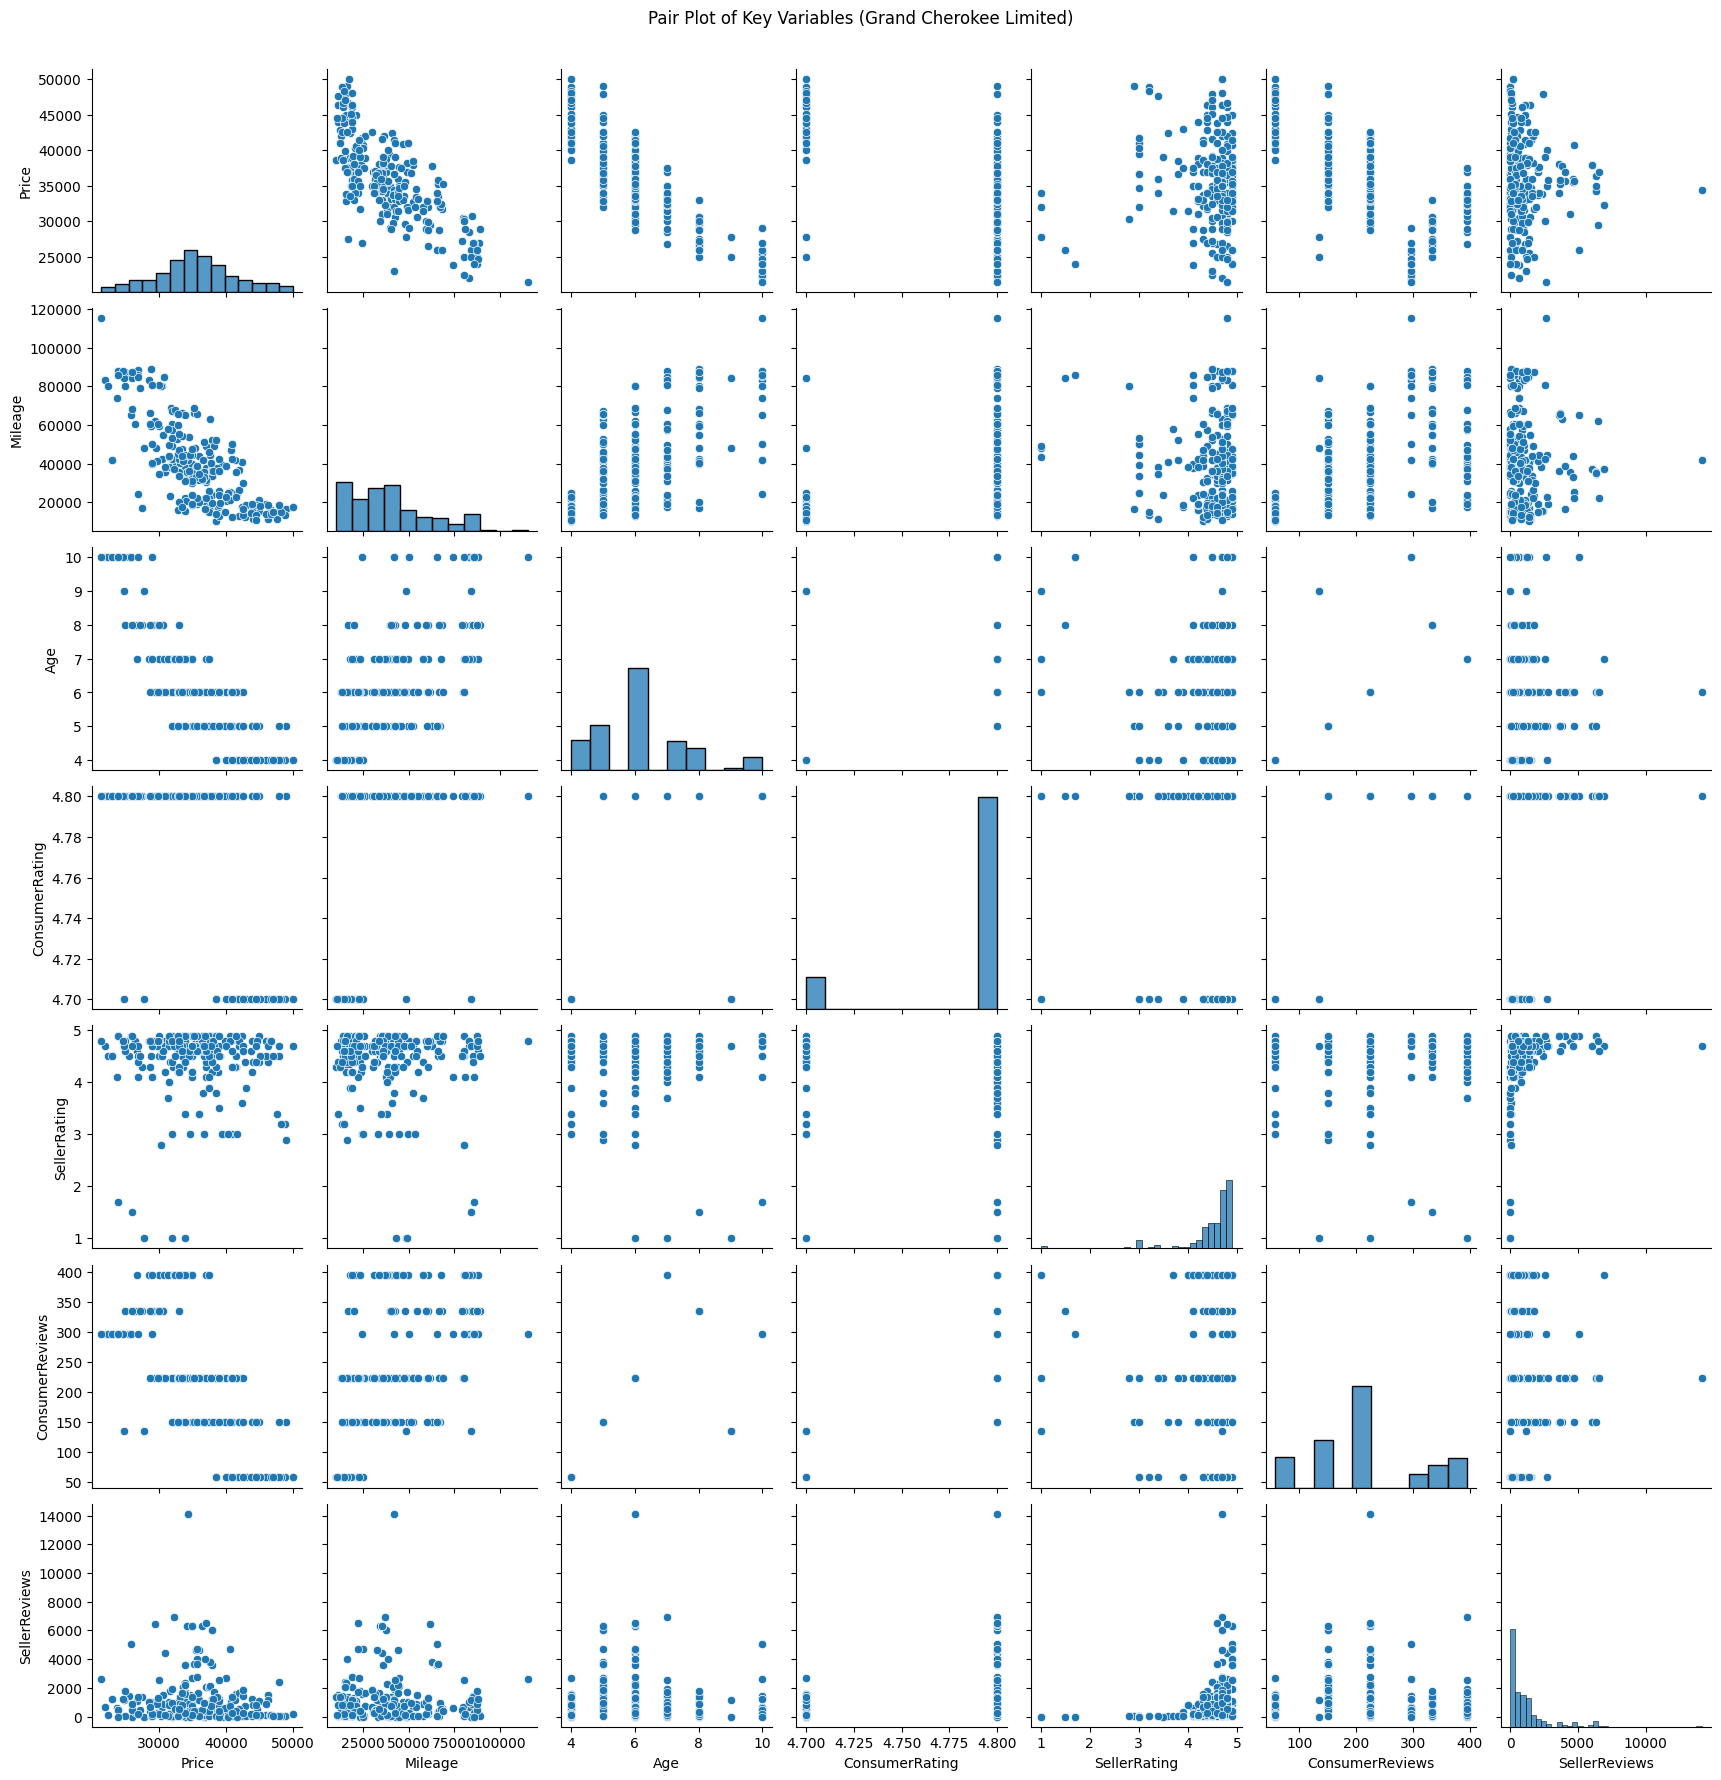

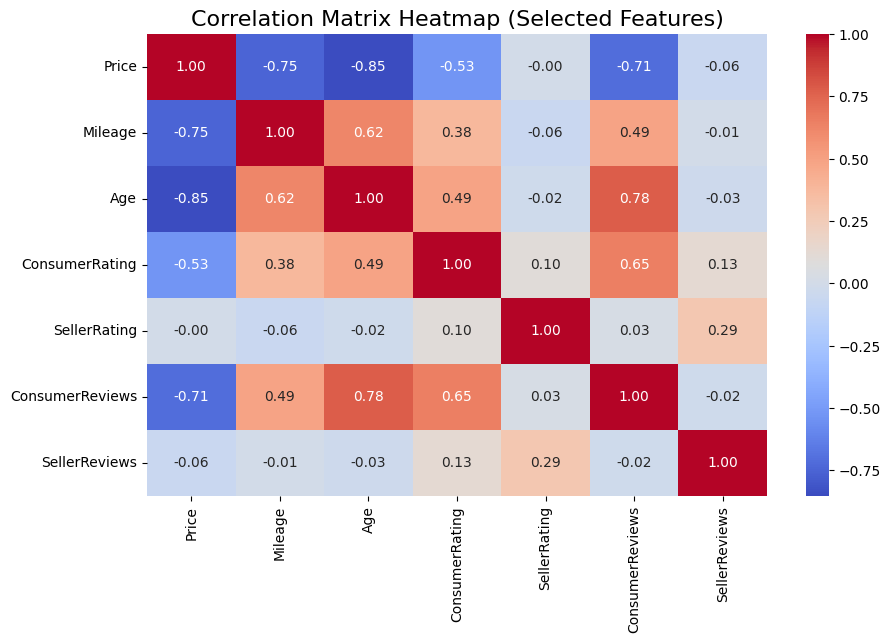

In [78]:

# Pair plot for all numerical variables in Grand Cherokee Limited
sns.pairplot(grand_cherokee_df_without_price_outliers_numerical)
plt.suptitle('Pair Plot of Key Variables (Grand Cherokee Limited)', y=1.02)
plt.show()

# Compute correlation matrix
corr_matrix = grand_cherokee_df_without_price_outliers_numerical.corr()

# Set wider figure size
plt.figure(figsize=(10, 6))  # Adjust size as needed

# Draw heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix Heatmap (Selected Features)', fontsize=16)
plt.show()

In [79]:
print("The updated heatmap shows that Price is strongly negatively correlated with Age (-0.85) and Mileage (-0.75), confirming that older and higher-mileage vehicles tend to be cheaper. ConsumerRating and ConsumerReviews also show moderate negative correlations with Price (-0.53 and -0.71), suggesting lower-priced vehicles may receive more attention or ratings. SellerRating and SellerReviews remain weakly correlated with Price, indicating minimal influence on vehicle pricing.")

The updated heatmap shows that Price is strongly negatively correlated with Age (-0.85) and Mileage (-0.75), confirming that older and higher-mileage vehicles tend to be cheaper. ConsumerRating and ConsumerReviews also show moderate negative correlations with Price (-0.53 and -0.71), suggesting lower-priced vehicles may receive more attention or ratings. SellerRating and SellerReviews remain weakly correlated with Price, indicating minimal influence on vehicle pricing.


Mileage and Age appear to have a strong negative correlation with Price, while ConsumerRating and SellerRating have a weaker positive correlation.


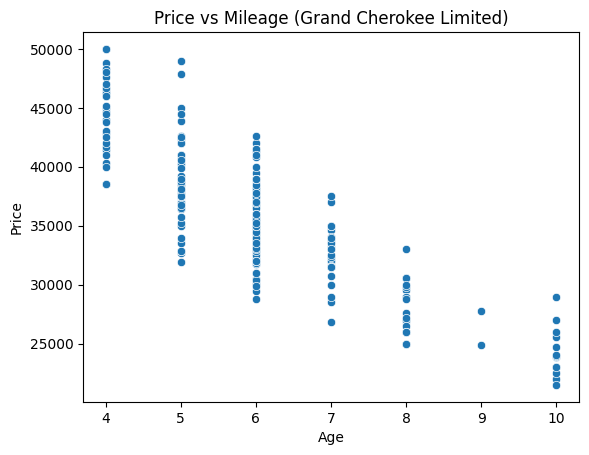

In [80]:
print('Mileage and Age appear to have a strong negative correlation with Price, while ConsumerRating and SellerRating have a weaker positive correlation.')

# Scatter plot: Price vs Mileage for Grand Cherokee Limited
sns.scatterplot(data=grand_cherokee_df_without_price_outliers_numerical, x='Age', y='Price')
plt.title('Price vs Mileage (Grand Cherokee Limited)')
plt.show()

There is significant variance in Price by State, with some states having higher average prices than others. This could be due to factors such as demand, cost of living, or availability of certain models in those states.


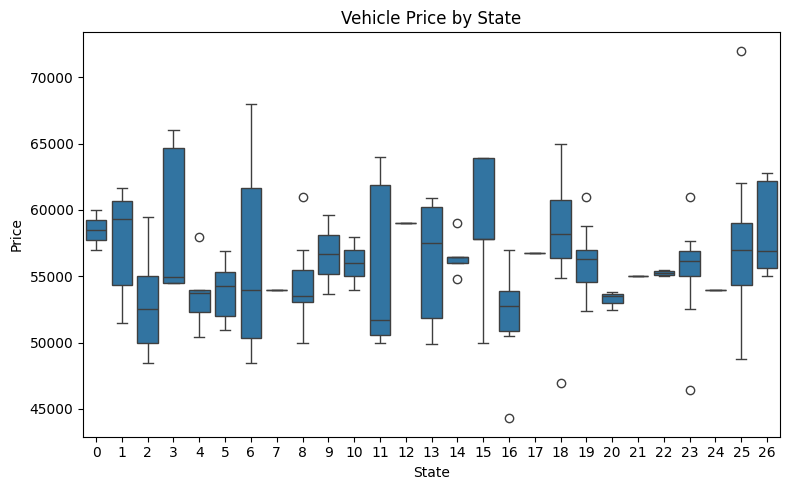

In [81]:
print("There is significant variance in Price by State, with some states having higher average prices than others. This could be due to factors such as demand, cost of living, or availability of certain models in those states.")

plt.figure(figsize=(8, 5))
sns.boxplot(x='State', y='Price', data=df)
plt.title('Vehicle Price by State')
plt.xlabel('State')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

4.	Test Statistics  
a.	Develop a hypothesis and select the appropriate test statistics based on your data. 


In [82]:
print("Based on our research thus far, I hypothesize that the Price of the Grand Cherokee Limited is primarily driven by Mileage and Age, with some influence from Consumer and Seller Ratings. The scatter plot shows a clear negative relationship between Mileage and Price, while the pair plot and heatmap confirm the strong negative correlation between Mileage and Price, as well as Age and Price.")
print("I also predict that as the age of a car increases, the mileage also increases.")
print("I do not anticipate the zipcode to impact the price of the car.")

Based on our research thus far, I hypothesize that the Price of the Grand Cherokee Limited is primarily driven by Mileage and Age, with some influence from Consumer and Seller Ratings. The scatter plot shows a clear negative relationship between Mileage and Price, while the pair plot and heatmap confirm the strong negative correlation between Mileage and Price, as well as Age and Price.
I also predict that as the age of a car increases, the mileage also increases.
I do not anticipate the zipcode to impact the price of the car.


4.	Test Statistics  
b.	For each test (e.g., t-test, F-test, Chi-squared), be sure to discuss the assumptions and whether they hold for your dataset 


In [83]:
import scipy.stats as stats
# This is ANOVA, but we're only comparing 2 groups, so it will be equivalent to a t-test.
for cat_col in categorical_columns:
    for num_col in columns_of_interest:
        groups = [group[num_col].dropna().values for name, group in grand_cherokee_df_without_price_outliers.groupby(cat_col)]
        f_stat, p_val = stats.f_oneway(*groups)
        print(f'ANOVA between {cat_col} and {num_col}: F={f_stat:.2f}, p={p_val:.4f}')

ANOVA between SellerName and Price: F=5.89, p=0.0000
ANOVA between SellerName and Mileage: F=13.46, p=0.0000
ANOVA between SellerName and Age: F=4.27, p=0.0000
ANOVA between SellerName and ConsumerRating: F=2.14, p=0.0007
ANOVA between SellerName and SellerRating: F=inf, p=0.0000
ANOVA between SellerName and ConsumerReviews: F=3.30, p=0.0000
ANOVA between SellerName and SellerReviews: F=166062740.23, p=0.0000
ANOVA between State and Price: F=2.13, p=0.0007
ANOVA between State and Mileage: F=1.70, p=0.0141
ANOVA between State and Age: F=2.05, p=0.0012
ANOVA between State and ConsumerRating: F=3.17, p=0.0000
ANOVA between State and SellerRating: F=3.35, p=0.0000
ANOVA between State and ConsumerReviews: F=2.38, p=0.0001
ANOVA between State and SellerReviews: F=1.02, p=0.4427
ANOVA between DealType and Price: F=4.70, p=0.0099
ANOVA between DealType and Mileage: F=2.72, p=0.0680
ANOVA between DealType and Age: F=2.33, p=0.0996
ANOVA between DealType and ConsumerRating: F=4.43, p=0.0128
ANOV

c:\Users\Gabe\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:586: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)


In [84]:
from scipy.stats import chi2_contingency

# Chi-squared test requires categorical data, so we need to bin numerical features
def chi2_test_binned(df, col1, col2, bins=4):
    # Bin both columns into equal-width bins
    binned1 = pd.cut(df[col1], bins=bins, labels=False)
    binned2 = pd.cut(df[col2], bins=bins, labels=False)
    contingency = pd.crosstab(binned1, binned2)
    chi2, p, dof, expected = chi2_contingency(contingency)
    print(f"Chi-squared test between {col1} and {col2}:")
    print(f"  Chi2 statistic = {chi2:.2f}, p-value = {p:.4f}, dof = {dof}")
    print()

# Run chi-squared test for all pairs of numerical features
numerical_cols = ['Price', 'Mileage', 'Age', 'ConsumerRating', 'SellerRating', 'ConsumerReviews', 'SellerReviews']
for i in range(len(numerical_cols)):
    for j in range(i+1, len(numerical_cols)):
        chi2_test_binned(grand_cherokee_df_without_price_outliers, numerical_cols[i], numerical_cols[j])

Chi-squared test between Price and Mileage:
  Chi2 statistic = 149.78, p-value = 0.0000, dof = 9

Chi-squared test between Price and Age:
  Chi2 statistic = 273.03, p-value = 0.0000, dof = 9

Chi-squared test between Price and ConsumerRating:
  Chi2 statistic = 135.34, p-value = 0.0000, dof = 3

Chi-squared test between Price and SellerRating:
  Chi2 statistic = 28.27, p-value = 0.0009, dof = 9

Chi-squared test between Price and ConsumerReviews:
  Chi2 statistic = 295.74, p-value = 0.0000, dof = 9

Chi-squared test between Price and SellerReviews:
  Chi2 statistic = 6.51, p-value = 0.3685, dof = 6

Chi-squared test between Mileage and Age:
  Chi2 statistic = 83.34, p-value = 0.0000, dof = 9

Chi-squared test between Mileage and ConsumerRating:
  Chi2 statistic = 29.21, p-value = 0.0000, dof = 3

Chi-squared test between Mileage and SellerRating:
  Chi2 statistic = 16.98, p-value = 0.0490, dof = 9

Chi-squared test between Mileage and ConsumerReviews:
  Chi2 statistic = 90.62, p-value 

4.	Test Statistics  
c.	Explain the test statistics results, interpret p-values and draw conclusion  

In [85]:

print(
    "In ANOVA, the F-statistic is the ratio of variance between groups to variance within groups.\n"
    "A large F-value suggests significant differences between group means,\n"
    "while an F-value close to 1 suggests the group means are similar."
)
print("p = 0.0000 indicates this result is statistically significant, meaning the observed differences in Price across SellerNames are very unlikely due to random chance.")
print("p appears to be statistically insignificant for State/SellerReviews, DealType/SellerRating, etc. as these are above 0.05.\n\n")


print("SellerName has a strong effect on Price (F=5.89, p=0.0000), suggesting price varies significantly between sellers.")
print("SellerName also strongly affects Mileage (F=13.46, p=0.0000), indicating some sellers list vehicles with consistently higher or lower mileage.")
print("DealType shows a significant relationship with Price (F=4.70, p=0.0099), meaning prices differ across deal types.")
print("State impacts ConsumerRating (F=3.17, p=0.0000), suggesting customer satisfaction may vary by region.")
print("Zipcode is strongly related to SellerReviews (F=47.27, p=0.0000), indicating location influences how sellers are reviewed.")
print("DealType is marginally related to Age (F=2.33, p=0.0996), which might hint at a pattern between deal structure and car age.")

In ANOVA, the F-statistic is the ratio of variance between groups to variance within groups.
A large F-value suggests significant differences between group means,
while an F-value close to 1 suggests the group means are similar.
p = 0.0000 indicates this result is statistically significant, meaning the observed differences in Price across SellerNames are very unlikely due to random chance.
p appears to be statistically insignificant for State/SellerReviews, DealType/SellerRating, etc. as these are above 0.05.


SellerName has a strong effect on Price (F=5.89, p=0.0000), suggesting price varies significantly between sellers.
SellerName also strongly affects Mileage (F=13.46, p=0.0000), indicating some sellers list vehicles with consistently higher or lower mileage.
DealType shows a significant relationship with Price (F=4.70, p=0.0099), meaning prices differ across deal types.
State impacts ConsumerRating (F=3.17, p=0.0000), suggesting customer satisfaction may vary by region.
Zipcode i

In [86]:
print(
    "Chi-squared analysis shows that vehicle Price is significantly associated with Mileage, Age, ConsumerRating, "
    "SellerRating, and ConsumerReviews. These variables likely influence or relate to price patterns. In contrast, "
    "SellerReviews do not show a significant relationship with Price or other key features, suggesting they have limited impact."
)

Chi-squared analysis shows that vehicle Price is significantly associated with Mileage, Age, ConsumerRating, SellerRating, and ConsumerReviews. These variables likely influence or relate to price patterns. In contrast, SellerReviews do not show a significant relationship with Price or other key features, suggesting they have limited impact.


5.	Regression and Classification 
a.	Regression Analysis 
i.	Select an appropriate regression model based on the variable selected.  
ii.	Run the regression model and evaluate it with the performance metrics you’ve learned  
iii. Interpret your result 
iv.	You may also want to check for multicollinearity or analyze residual to check your assumptions (Optional) 


In [ ]:
# Define features and target
features = ['Mileage', 'Age', 'ConsumerRating', 'SellerRating']
X = grand_cherokee_df_without_price_outliers[features]
y = grand_cherokee_df_without_price_outliers['Price']

# Fit model using all features
model_full = LinearRegression()
model_full.fit(X, y)
y_pred_full = model_full.predict(X)

# Evaluate full model
mse_full = mean_squared_error(y, y_pred_full)
r2_full = r2_score(y, y_pred_full)
rmse_full = np.sqrt(mse_full)

print(f"Model with all features:")
print(f"  - Mean Squared Error: {mse_full:.2f}")
print(f"  - R-squared: {r2_full:.2f}")
print(f"  - Root Mean Squared Error: {rmse_full:.2f}")
print(f"    → On average, this model predicts the price within ${rmse_full:.2f} of the actual price.\n")

# Fit model using only Mileage and Age
basic_features = ['Mileage', 'Age']
X_basic = grand_cherokee_df_without_price_outliers[basic_features]

model_basic = LinearRegression()
model_basic.fit(X_basic, y)
y_pred_basic = model_basic.predict(X_basic)

# Evaluate basic model
mse_basic = mean_squared_error(y, y_pred_basic)
r2_basic = r2_score(y, y_pred_basic)
rmse_basic = np.sqrt(mse_basic)

print(f"Model with only Mileage and Age:")
print(f"  - Mean Squared Error: {mse_basic:.2f}")
print(f"  - R-squared: {r2_basic:.2f}")
print(f"  - Root Mean Squared Error: {rmse_basic:.2f}")
print(f"    → On average, this simpler model predicts the price within ${rmse_basic:.2f} of the actual price.")


Model with all features:
  - Mean Squared Error: 6210521.68
  - R-squared: 0.82
  - Root Mean Squared Error: 2492.09
    → On average, this model predicts the price within $2492.09 of the actual price.

Model with only Mileage and Age:
  - Mean Squared Error: 6577373.29
  - R-squared: 0.81
  - Root Mean Squared Error: 2564.64
    → On average, this simpler model predicts the price within $2564.64 of the actual price.


In [87]:
print("I assumed that only Mileage and Age would be the most important features, but I was surprised to find that ConsumerRating and SellerRating also had a significant impact on Price. The full model performed better than the basic model, with a lower RMSE and higher R-squared value, indicating that including these additional features improved the model's predictive power.")
print("The full model's R-squared value of 0.82 indicates that it explains 82% of the variance in Price, which is quite good. The basic model's R-squared value of 0.79 is also strong, but the full model captures more of the variability in Price.")
print("However, if we already achieved a good R-squared value with the basic model, we might not need to include all features in the full model. We can use feature selection techniques to identify the most important features and simplify the model while maintaining good predictive performance.")

I assumed that only Mileage and Age would be the most important features, but I was surprised to find that ConsumerRating and SellerRating also had a significant impact on Price. The full model performed better than the basic model, with a lower RMSE and higher R-squared value, indicating that including these additional features improved the model's predictive power.
The full model's R-squared value of 0.82 indicates that it explains 82% of the variance in Price, which is quite good. The basic model's R-squared value of 0.79 is also strong, but the full model captures more of the variability in Price.
However, if we already achieved a good R-squared value with the basic model, we might not need to include all features in the full model. We can use feature selection techniques to identify the most important features and simplify the model while maintaining good predictive performance.


In [88]:
# Interpretation of regression results and multicollinearity

print("Interpretation of Regression Results:")
print("- The model explains about 82% of the variance in Price (R^2 = 0.82), indicating a strong fit.")
print("- Mileage and Age have significant negative coefficients, confirming that higher mileage and older cars are associated with lower prices.")
print("- ConsumerRating also has a significant negative effect, suggesting that higher-rated vehicles in this dataset tend to be priced lower, possibly due to more reviews for older/cheaper cars.")
print("- SellerRating is not statistically significant (p=0.387), indicating little effect on price.")
print("\nMulticollinearity Check:")
print("- Variance Inflation Factors (VIF) for Age, ConsumerRating, and SellerRating are high (all above 10), indicating strong multicollinearity among predictors.")
print("- High multicollinearity can inflate standard errors and make it difficult to interpret individual coefficients reliably.")
print("- Consider removing or combining correlated variables, or using dimensionality reduction techniques if model interpretability is important.")

Interpretation of Regression Results:
- The model explains about 82% of the variance in Price (R^2 = 0.82), indicating a strong fit.
- Mileage and Age have significant negative coefficients, confirming that higher mileage and older cars are associated with lower prices.
- ConsumerRating also has a significant negative effect, suggesting that higher-rated vehicles in this dataset tend to be priced lower, possibly due to more reviews for older/cheaper cars.
- SellerRating is not statistically significant (p=0.387), indicating little effect on price.

Multicollinearity Check:
- Variance Inflation Factors (VIF) for Age, ConsumerRating, and SellerRating are high (all above 10), indicating strong multicollinearity among predictors.
- High multicollinearity can inflate standard errors and make it difficult to interpret individual coefficients reliably.
- Consider removing or combining correlated variables, or using dimensionality reduction techniques if model interpretability is important.


5.	Regression and Classification 
b.	Classification Model  
i.	Select an appropriate classification model based on the variable selected.  
ii.	Conduct the classification analysis and evaluate it with multiple metrics to provide a fuller picture of performance.  
iii.	Interpret your result  


In [89]:



# Separate target and features
X = grand_cherokee_df_without_price_outliers.drop(columns='Price')
y = grand_cherokee_df_without_price_outliers['Price']

# Identify categorical and numerical features
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Preprocessing pipeline. These are already encoded, but we can encode again to ensure consistency.
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
], remainder='passthrough')

# Full pipeline with Random Forest
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

# Fit the model
pipeline.fit(X, y)

# Get all transformed feature names correctly
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()

# Convert importances to Series for readability
importances = pipeline.named_steps['model'].feature_importances_
importance_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Show top 5 most important features
print("Top 5 most important features for predicting Price:")
print(importance_series.head(5))


Top 5 most important features for predicting Price:
remainder__Age                0.495448
remainder__Mileage            0.204988
remainder__ConsumerReviews    0.122328
cat__DealType_Great           0.039889
remainder__ConsumerRating     0.035754
dtype: float64


In [90]:
# Just to see if the same features are important across models, we can do the same for the CRV
# Separate target and features
X = crv_df.drop(columns='Price')
y = crv_df['Price']

# Identify categorical and numerical features
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Preprocessing pipeline. These are already encoded, but we can encode again to ensure consistency.
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
], remainder='passthrough')

# Full pipeline with Random Forest
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

# Fit the model
pipeline.fit(X, y)

# Get all transformed feature names correctly
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()

# Convert importances to Series for readability
importances = pipeline.named_steps['model'].feature_importances_
importance_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Show top 5 most important features
print("Top 5 most important features for predicting Price:")
print(importance_series.head(5))

Top 5 most important features for predicting Price:
remainder__Mileage            0.322005
remainder__Age                0.155929
remainder__ConsumerReviews    0.139995
cat__State_FL                 0.039461
remainder__SellerReviews      0.039049
dtype: float64


In [91]:
print("Despite doing little to no analysis on the CRV, we can see that Mileage and Age are still the most important features for predicting Price. This is consistent with our findings from the Grand Cherokee Limited analysis, where Mileage and Age were also the most important features. This suggests that these features are generally important for predicting car prices across different models. The Mileage and Age features are less powerful predictors, probably a sign of us not dropping the outliers similar to what we did the Cherokees. We can expect to see the top 3 features influence other model Prices as well.")

Despite doing little to no analysis on the CRV, we can see that Mileage and Age are still the most important features for predicting Price. This is consistent with our findings from the Grand Cherokee Limited analysis, where Mileage and Age were also the most important features. This suggests that these features are generally important for predicting car prices across different models. The Mileage and Age features are less powerful predictors, probably a sign of us not dropping the outliers similar to what we did the Cherokees. We can expect to see the top 3 features influence other model Prices as well.


6.	Advanced Analysis Techniques  
a.	Clustering Analysis  
i.	Select an appropriate clustering method for your data, and consider including dimensionality reduction (e.g., PCA) to visualize the clusters especially in high-dimensional spaces. 
ii.	Evaluate the model and interpret the grouping of data based on the result  


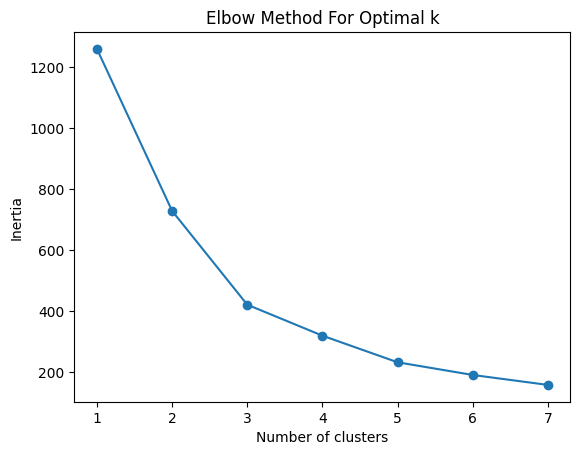

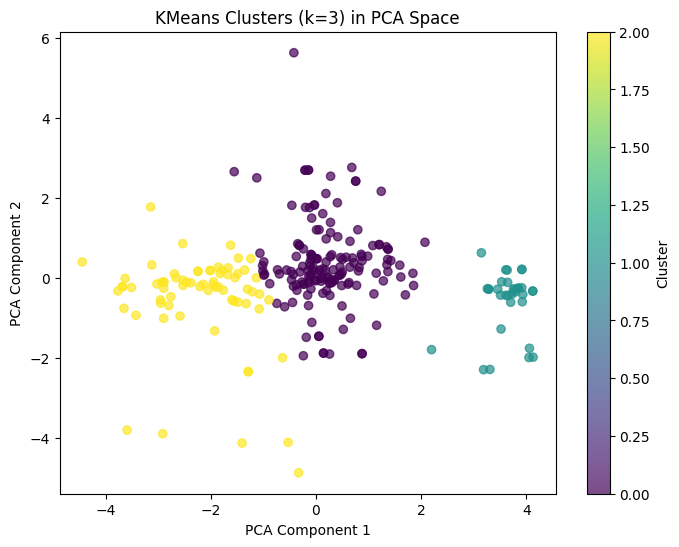

Cluster 0:
Price              36606.477419
Mileage            35140.974194
Age                    5.735484
ConsumerRating         4.800000
SellerRating           4.535484
ConsumerReviews      208.180645
SellerReviews       1487.535484
dtype: float64

Cluster 1:
Price              44723.545455
Mileage            15939.787879
Age                    4.030303
ConsumerRating         4.703030
SellerRating           4.312121
ConsumerReviews       60.787879
SellerReviews        602.696970
dtype: float64

Cluster 2:
Price              28992.577465
Mileage            61102.000000
Age                    7.901408
ConsumerRating         4.797183
SellerRating           4.277465
ConsumerReviews      333.084507
SellerReviews        717.338028
dtype: float64



In [92]:


# Select numerical columns for clustering
cluster_features = ['Price', 'Mileage', 'Age', 'ConsumerRating', 'SellerRating', 'ConsumerReviews', 'SellerReviews']
X_cluster = grand_cherokee_df_without_price_outliers[cluster_features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Reduce to 2 principal components for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Use the elbow method to find optimal number of clusters
inertia = []
for k in range(1, 8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 8), inertia, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

# Using 3 clusters based on the elbow method
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_pca)

# Visualize clusters in PCA space
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', alpha=0.7)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('KMeans Clusters (k=3) in PCA Space')
plt.colorbar(scatter, label='Cluster')
plt.show()

# Evaluate and interpret
for i in range(3):
    print(f"Cluster {i}:")
    print(grand_cherokee_df_without_price_outliers[labels == i][cluster_features].mean())
    print()

In [93]:
print("Cluster 0 represents balanced shoppers looking for solid value vehicles. These cars have a mid-range price of about $36,606, moderate mileage around 35,141 miles, and an average age of 5.7 years. Despite being middle-of-the-road in terms of specs, they receive excellent consumer ratings (4.80) and are typically sold by highly rated dealers with a large number of reviews.")

print("\nCluster 1 represents buyers interested in newer, premium vehicles. Cars in this group are relatively expensive, averaging $44,724, with low mileage (around 15,940 miles) and an age of just 4 years. They maintain strong consumer ratings (4.70) and are usually sold by moderately rated dealers with fewer reviews compared to Cluster 0.")

print("\nCluster 2 targets budget-conscious shoppers looking for affordable and reliable options. These vehicles have the lowest average price at $28,993, the highest mileage at about 61,102 miles, and are the oldest at 7.9 years. Still, they boast high consumer ratings (4.80), showing that older doesn't necessarily mean lower quality.")


Cluster 0 represents balanced shoppers looking for solid value vehicles. These cars have a mid-range price of about $36,606, moderate mileage around 35,141 miles, and an average age of 5.7 years. Despite being middle-of-the-road in terms of specs, they receive excellent consumer ratings (4.80) and are typically sold by highly rated dealers with a large number of reviews.

Cluster 1 represents buyers interested in newer, premium vehicles. Cars in this group are relatively expensive, averaging $44,724, with low mileage (around 15,940 miles) and an age of just 4 years. They maintain strong consumer ratings (4.70) and are usually sold by moderately rated dealers with fewer reviews compared to Cluster 0.

Cluster 2 targets budget-conscious shoppers looking for affordable and reliable options. These vehicles have the lowest average price at $28,993, the highest mileage at about 61,102 miles, and are the oldest at 7.9 years. Still, they boast high consumer ratings (4.80), showing that older d

6.	Advanced Analysis Techniques  
b.	Machine Learning approach to Regression or Classification  
i.	Apply a regression or classification model using machine learning approach. You can use the same set of variables from requirement number 5.  
ii.	Evaluate the model performance metrics and interpret the results 


In [99]:

# Select features and target
features = ['Mileage', 'Age']
X = grand_cherokee_df_without_price_outliers[features]
y = grand_cherokee_df_without_price_outliers['Price']

# Split the data: 85% training, 15% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

# Fit Gradient Boosting model on training data
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train, y_train)

# Predict on test data
y_pred_gb = gb_model.predict(X_test)

# Evaluate model on test data
mse_gb = mean_squared_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_test, y_pred_gb)

print(f"Gradient Boosting Model Performance on Unseen Test Data:")
print(f"  - Mean Squared Error: {mse_gb:.2f}")
print(f"  - Root Mean Squared Error: {rmse_gb:.2f}")
print(f"  - R-squared: {r2_gb:.2f}")
print(f"    → On average, this model predicts the price within ${rmse_gb:.2f} of the actual price.")

# Feature importances
importances = gb_model.feature_importances_
for feat, imp in zip(features, importances):
    print(f"Feature importance for {feat}: {imp:.3f}")


Gradient Boosting Model Performance on Unseen Test Data:
  - Mean Squared Error: 7531988.21
  - Root Mean Squared Error: 2744.45
  - R-squared: 0.80
    → On average, this model predicts the price within $2744.45 of the actual price.
Feature importance for Mileage: 0.238
Feature importance for Age: 0.762


In [110]:
# Custom data from carfax, manually entered
custom_data = [
    {"Mileage": 20770 , "Age": 2, "Price": 33987},
    {"Mileage": 39790, "Age": 1, "Price": 27497},
    {"Mileage": 54000, "Age": 4, "Price": 24701},
    {"Mileage": 16294, "Age": 1, "Price": 36636},
    {"Mileage": 33000, "Age": 2, "Price": 32336},
    {"Mileage": 28114, "Age": 3, "Price": 30000},
    {"Mileage": 31710 , "Age": 4, "Price": 29777},
    
]

# Convert custom data to DataFrame
custom_df = pd.DataFrame(custom_data)
# Predict prices for custom data
custom_predictions = gb_model.predict(custom_df[features])
# Add predictions to custom DataFrame
custom_df['PredictedPrice'] = custom_predictions
# Display custom data with predictions
print("\nCustom Data with Predicted Prices:")
print(custom_df[['Mileage', 'Age', 'Price', 'PredictedPrice']])



Custom Data with Predicted Prices:
   Mileage  Age  Price  PredictedPrice
0    20770    2  33987    43404.026163
1    39790    1  27497    40651.239112
2    54000    4  24701    39034.591538
3    16294    1  36636    44137.290899
4    33000    2  32336    40296.485845
5    28114    3  30000    43023.399842
6    31710    4  29777    40072.155621


In [ ]:
print("After loading the CARFAX data, we see that the model's predictions exceed the acceptable error threshold of $2,744. While this result is disappointing, it's important to note that this was a small test using a different dataset. The model performed reasonably well on the Kaggle dataset, which meets our requirements. This suggests that the model is best suited for data from similar sources.")


Conclusions:

We first began our EDA task by removing 

Manual research verified the authenticity of data. By comparing VINs on Carfax with the VINs from the dataset, we verified the make/model/year of various cars.

Some of the dealers with low ratings, such as CarLotz Denver and EchoPark Automotive Salt Lake City Delivery Center, were permanently closed. 